<a href="https://colab.research.google.com/github/JonathanMtz1103987/Simulaci-n-estocastica/blob/main/Tarea_3_Encuesta_Estudiantil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Participación estudiantil en encuesta universitaria

**Simulación computacional y análisis de resultados**  
Jonathan Martínez Pérez

Simulación Estocástica

Facultad de Ciencias Exactas · Universidad Juárez del Estado de Durango  

## Descripción del problema

La coordinación de la universidad quiere reunir al menos 60 cuestionarios completos para conocer la opinión de sus estudiantes sobre los servicios universitarios. Planea invitar a 100 estudiantes distintos y dejar abierta la encuesta durante una semana. Para organizar el envío interesa saber tanto cuántas respuestas puede esperar como qué tan frecuente sería quedarse por debajo de la meta.

**Objetivo.** Estimar mediante Monte Carlo la media de respuestas por convocatoria y la probabilidad de reunir al menos 60 y determinar el menor número de invitaciones con el que la probabilidad de lograr la meta alcanza el 95 %.

Para el ejercicio se fijara una probabilidad individual de respuesta de 0.60**, constante e independiente entre estudiantes.

## Modelo y simulación

Para cada estudiante, $I_i=1$ si completa la encuesta a tiempo y $I_i=0$ en otro caso. Si hay $n$ invitaciones y la probabilidad individual es $p$, el conteo de respuestas completas $X$ sigue una distribución binomial:

$$
X=\sum_{i=1}^{n} I_i,\qquad X\sim\operatorname{Binomial}(n,p),\qquad X\in\{0,1,\ldots,n\}.
$$

Con 100 invitaciones y $p=0.60$, la media teórica es $np=60$ y la desviación estándar teórica es $\sqrt{np(1-p)}=\sqrt{24}\approx4.90$ respuestas. Son referencias para comprobar la simulación. La probabilidad de cumplir la meta incluye convocatorias con exactamente 60 respuestas.


In [2]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy.stats import binom, norm
from IPython.display import display, Markdown

SEMILLA = 42
REPLICAS = 10_000
INVITACIONES = 100
P_RESPUESTA = 0.60
META_RESPUESTAS = 60
PROB_OBJETIVO = 0.95

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__}")
print(f"SciPy {scipy.__version__} | Matplotlib {matplotlib.__version__} | Semilla {SEMILLA}")

Python 3.13.18 | NumPy 2.4.6 | pandas 2.2.3
SciPy 1.16.3 | Matplotlib 3.10.0 | Semilla 42


Se simularon 10,000 convocatorias independientes. Cada número generado representa cuántas personas respondieron en una convocatoria. Se comprueba que haya una observación por réplica y que el conteo sea posible.

In [3]:
rng = np.random.default_rng(SEMILLA)
respuestas = rng.binomial(n=INVITACIONES, p=P_RESPUESTA, size=REPLICAS)

assert respuestas.size == REPLICAS
assert np.all((respuestas >= 0) & (respuestas <= INVITACIONES))
print(f"Convocatorias simuladas: {respuestas.size:,}")
print("Respuestas en las primeras diez convocatorias:", respuestas[:10].tolist())

Convocatorias simuladas: 10,000
Respuestas en las primeras diez convocatorias: [54, 69, 66, 61, 60, 66, 62, 69, 55, 54]


## Análisis estadístico

La media $\bar X$ nos estima el número esperado de respuestas, la desviación estándar muestral $s$ describe la variación entre convocatorias, el error estándar $s/\sqrt{B}$  la precisión de la media calculada con $B$ réplicas independientes y con $B=10{,}000$ el teorema central del límite justifica el intervalo de confianza aproximado del 95 % para la media:
# Sección nueva
$$
\bar X \;\pm\; 1.96\,\frac{s}{\sqrt B}.
$$

Usamos las mismas réplicas para estimar la probabilidad de cumplir la meta, dividiendo el número de convocatorias que la alcanzan entre el total de convocatorias simuladas.

In [5]:
media = respuestas.mean()
desviacion = respuestas.std(ddof=1)
error_estandar = desviacion / np.sqrt(REPLICAS)
margen = norm.ppf(0.975) * error_estandar
ic_inferior, ic_superior = media - margen, media + margen
alcanzan_meta = np.count_nonzero(respuestas >= META_RESPUESTAS)
prob_base = alcanzan_meta / REPLICAS

resumen = pd.Series({
    "Media": media,
    "Desviación estándar muestral": desviacion,
    "Mínimo observado": respuestas.min(),
    "Máximo observado": respuestas.max(),
    "Error estándar de la media": error_estandar,
    "Límite inferior del IC del 95 % ": ic_inferior,
    "Límite superior del IC del 95 % ": ic_superior
}, name="Respuestas por convocatoria")
display(resumen.round(4).to_frame())
print(f"Meta alcanzada: {alcanzan_meta:,} de {REPLICAS:,} convocatorias ({prob_base:.2%}).")

,Respuestas por convocatoria
Media,60.0351
Desviación estándar muestral,4.8783
Mínimo observado,41.0000
Máximo observado,79.0000
Error estándar de la media,0.0488
Límite inferior del IC del 95 %,59.9395
Límite superior del IC del 95 %,60.1307


Meta alcanzada: 5,473 de 10,000 convocatorias (54.73%).


##  Resultados

Distribución del número de respuestas.

 Cada barra indica el porcentaje de convocatorias con un conteo dado. El cambio de color separa las convocatorias por debajo de la meta de aquellas que la alcanzan.

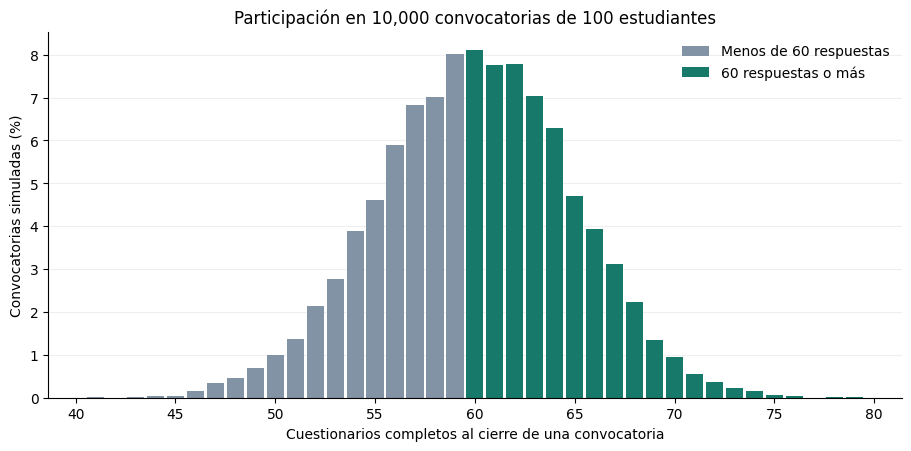

In [7]:
conteos, frecuencias = np.unique(respuestas, return_counts=True)
porcentajes = 100 * frecuencias / REPLICAS
cumplen = conteos >= META_RESPUESTAS

fig, ax = plt.subplots(figsize=(9, 4.4), layout="constrained")
ax.bar(conteos[~cumplen], porcentajes[~cumplen], width=0.86,
       color="#8293A6", label=f"Menos de {META_RESPUESTAS} respuestas")
ax.bar(conteos[cumplen], porcentajes[cumplen], width=0.86,
       color="#177969", label=f"{META_RESPUESTAS} respuestas o más")
ax.set(title=f"Participación en {REPLICAS:,} convocatorias de {INVITACIONES} estudiantes",
       xlabel="Cuestionarios completos al cierre de una convocatoria",
       ylabel="Convocatorias simuladas (%)")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.20)
ax.set_axisbelow(True)
ax.legend(frameon=False)
plt.show()

**Comparación** ¿Cuánto aumenta la probabilidad de alcanzar la meta al invitar a más estudiantes?

 La binomial da una referencia exacta: $P(X\geq m)=1-P(X\leq m-1)$ para una meta de $m$ respuestas. A partir de $m$ invitaciones, buscamos el primer tamaño con una probabilidad de alcanzar el 95 %. Al añadir una persona, la cantidad de respuestas anteriores se conserva o aumenta en una, de modo que la probabilidad de llegar a la meta es creciente en el número de invitaciones.

La tabla contrasta el plan inicial, el mínimo teórico y el tamaño inmediatamente anterior.

Para cada plan adicional se simulan otras 10,000 convocatorias. La comparación permite ver cuánto cambia el resultado por azar de Monte Carlo cerca del umbral.

In [11]:
# sf(m - 1) incluye exactamente m respuestas entre los casos favorables.
minimo_invitaciones = META_RESPUESTAS
while binom.sf(META_RESPUESTAS - 1, minimo_invitaciones, P_RESPUESTA) < PROB_OBJETIVO:
    minimo_invitaciones += 1

planes = sorted({INVITACIONES, minimo_invitaciones - 1, minimo_invitaciones})
# Un segundo flujo derivado de la semilla 42 permite repetir esta celda por separado.
rng_planes = np.random.default_rng([SEMILLA, 1])
filas = []
for n in planes:
    if n == INVITACIONES:
        muestra = respuestas
    else:muestra = rng_planes.binomial(n=n, p=P_RESPUESTA, size=REPLICAS)
    filas.append({"Invitaciones": n,
        "Media de respuestas": muestra.mean(),
        "Convocatorias que logran la meta": np.count_nonzero(muestra >= META_RESPUESTAS),
        "Logro simulado (%)": 100 * np.mean(muestra >= META_RESPUESTAS),
        "Logro exacto binomial (%)": 100 * binom.sf(META_RESPUESTAS - 1, n, P_RESPUESTA)})
comparacion = pd.DataFrame(filas).set_index("Invitaciones")
display(comparacion.round(2))

,Media de respuestas,Convocatorias que logran la meta,Logro simulado (%),Logro exacto binomial (%)
Invitaciones,,,,
100,60.04,5473,54.73,54.33
113,67.73,9407,94.07,94.36
114,68.40,9539,95.39,95.47


## 5. Conclusiónes

La interpretación se calcula a partir de las salidas anteriores para que los conteos, porcentajes e intervalos correspondan a la ejecución.

In [21]:
previo = minimo_invitaciones - 1
logro_previo = comparacion.loc[previo, "Logro exacto binomial (%)"]
logro_minimo = comparacion.loc[minimo_invitaciones, "Logro exacto binomial (%)"]
logro_mc = comparacion.loc[minimo_invitaciones, "Logro simulado (%)"]
display(comparacion.loc[previo, "Logro exacto binomial (%)"],comparacion.loc[minimo_invitaciones, "Logro exacto binomial (%)"],comparacion.loc[minimo_invitaciones, "Logro simulado (%)"])


np.float64(94.36271387450023)

np.float64(95.4680898566517)

np.float64(95.39)

**Participación esperada** Con 100 invitaciones se obtuvieron en promedio 60.04 respuestas, con un IC del 95 % para la media de 59.94 a 60.13. El intervalo mide la precisión de la simulación al estimar la media del modelo. Una convocatoria individual presentó mayor variación: la desviación estándar fue de 4.88 respuestas y los resultados observados fueron de 41 a 79.

**Gráfica** Las barras verdes reúnen el 54.73% de las convocatorias. Aunque la media está cerca de la meta, en el 45.27% de los envíos se recibieron menos de 60 cuestionarios completos.

**Decisión** Con una probabilidad individual de respuesta de 60%, el plan de 113 invitaciones alcanza la meta con una probabilidad teórica del 94.36 %. Con 114 invitaciones, esa probabilidad sube a 95.47 % (95.39 % en la simulación). Así, 114 es el menor número de invitaciones que cumple el criterio de planeación del 95% bajo estos supuestos.
